**1- Introducción y objetivo**

Descripción del problema:

Las campañas de marketing bancario buscan contactar a clientes para ofrecerles productos financieros. Sin embargo, no todos los clientes responden de la misma manera a estas campañas.

En este trabajo se utilizará un conjunto de datos de marketing bancario para desarrollar modelos de clasificación que permitan predecir si un cliente contratará un depósito a plazo.

**Objetivo**

El objetivo es comparar dos modelos de aprendizaje automático, la regresión logística y el árbol de decisión, para determinar cuál obtiene mejores resultados en la predicción de la respuesta de los clientes.

Para realizar la comparación, ambos modelos se entrenarán y evaluarán utilizando los mismos datos y las mismas métricas.


**2- Carga y exploración de datos**


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

df = pd.read_csv("dataset/bank.csv", sep=";")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB


In [3]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [4]:
df["y"].value_counts()

y
no     4000
yes     521
Name: count, dtype: int64

El conjunto de datos presenta un desequilibrio entre las clases: hay 4000 respuestas no y 521 respuestas yes. Por eso, la exactitud general no es suficiente para evaluar el rendimiento de los modelos.

**3. Preparación de los datos**


In [5]:
X = df.drop(columns=["y", "duration"])
y = df["y"]

In [6]:
numericas = X.select_dtypes(include="number").columns
categoricas = X.select_dtypes(exclude="number").columns

print("Variables numéricas:", list(numericas))
print("Variables categóricas:", list(categoricas))

Variables numéricas: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [7]:
preprocesamiento = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), numericas),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
    ]
)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))

Registros para entrenamiento: 3616
Registros para prueba: 905


Se excluyó la variable `duration` porque representa la duración de la llamada y no estaría disponible antes de contactar al cliente. Las variables numéricas se estandarizaron y las categóricas se transformaron mediante One-Hot Encoding. Finalmente, se utilizaron los mismos datos de entrenamiento y prueba para ambos modelos.


**4- Modelo 1: Regresión logística**

In [9]:
modelo_logistico = Pipeline(steps=[
    ("preprocesamiento", preprocesamiento),
    ("modelo", LogisticRegression(max_iter=1000, random_state=42))
])

modelo_logistico.fit(X_train, y_train)

predicciones_logistico = modelo_logistico.predict(X_test)

print("Exactitud:", accuracy_score(y_test, predicciones_logistico))
print("\nInforme de clasificación:")
print(classification_report(y_test, predicciones_logistico))

Exactitud: 0.887292817679558

Informe de clasificación:
              precision    recall  f1-score   support

          no       0.90      0.98      0.94       801
         yes       0.53      0.15      0.24       104

    accuracy                           0.89       905
   macro avg       0.72      0.57      0.59       905
weighted avg       0.86      0.89      0.86       905



La regresión logística obtuvo una exactitud del 88,7 %. Sin embargo, su recall para la clase `yes` fue del 15 %, lo que significa que detectó solo una pequeña proporción de los clientes que contrataron el depósito a plazo. Su precisión para esta clase fue del 53 %.



**5- Modelo 2: Árbol de decisión**

In [10]:
modelo_arbol = Pipeline(steps=[
    ("preprocesamiento", preprocesamiento),
    ("modelo", DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ))
])

modelo_arbol.fit(X_train, y_train)

predicciones_arbol = modelo_arbol.predict(X_test)

print("Exactitud:", accuracy_score(y_test, predicciones_arbol))
print("\nInforme de clasificación:")
print(classification_report(y_test, predicciones_arbol))

Exactitud: 0.7723756906077348

Informe de clasificación:
              precision    recall  f1-score   support

          no       0.91      0.82      0.86       801
         yes       0.23      0.41      0.29       104

    accuracy                           0.77       905
   macro avg       0.57      0.62      0.58       905
weighted avg       0.84      0.77      0.80       905



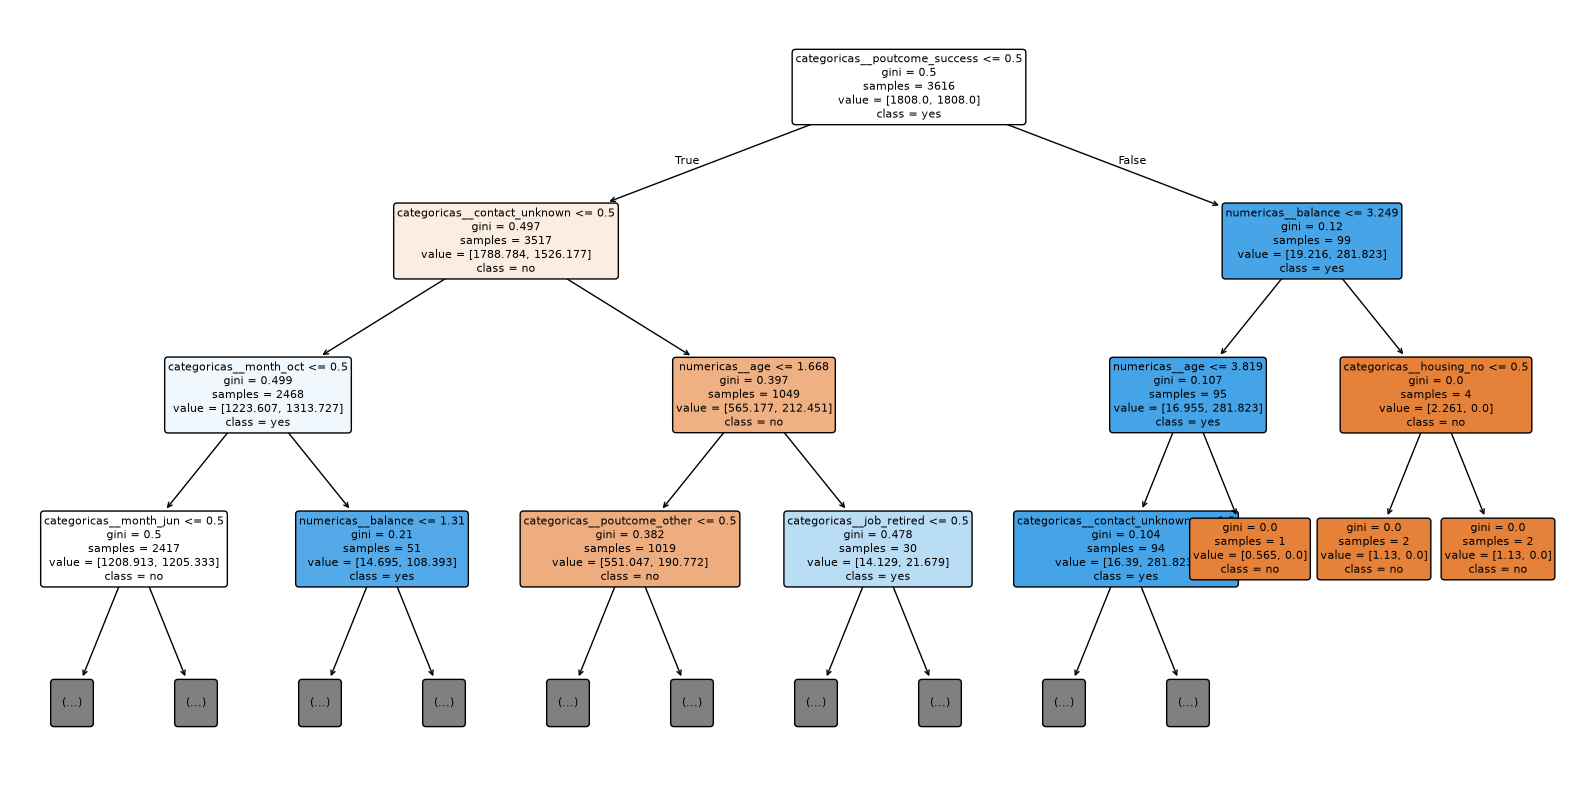

In [11]:
arbol = modelo_arbol.named_steps["modelo"]

plt.figure(figsize=(20, 10))
plot_tree(
    arbol,
    feature_names=modelo_arbol.named_steps["preprocesamiento"].get_feature_names_out(),
    class_names=["no", "yes"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.show()

El árbol de decisión obtuvo una exactitud del 77,2 %, inferior a la de la regresión logística. Sin embargo, alcanzó un recall del 41 % para la clase `yes`, por lo que detectó una mayor proporción de los clientes que contrataron el depósito. Su precisión para esta clase fue del 23 %.


**6. Comparación de resultados**

In [12]:
comparacion = pd.DataFrame({
    "Modelo": ["Regresión logística", "Árbol de decisión"],
    "Exactitud": [
        accuracy_score(y_test, predicciones_logistico),
        accuracy_score(y_test, predicciones_arbol)
    ],
    "Precisión (yes)": [
        precision_score(y_test, predicciones_logistico, pos_label="yes"),
        precision_score(y_test, predicciones_arbol, pos_label="yes")
    ],
    "Recall (yes)": [
        recall_score(y_test, predicciones_logistico, pos_label="yes"),
        recall_score(y_test, predicciones_arbol, pos_label="yes")
    ],
    "F1-score (yes)": [
        f1_score(y_test, predicciones_logistico, pos_label="yes"),
        f1_score(y_test, predicciones_arbol, pos_label="yes")
    ]
})

comparacion.round(2)

,Modelo,Exactitud,Precisión (yes),Recall (yes),F1-score (yes)
0,Regresión logística,0.89,0.53,0.15,0.24
1,Árbol de decisión,0.77,0.23,0.41,0.29


La regresión logística obtuvo mejores resultados en exactitud y precisión para la clase `yes`. En cambio, el árbol de decisión alcanzó un mayor recall y un mejor F1-score para esa clase. Esto indica que existe una diferencia entre obtener más predicciones correctas en general y detectar una mayor proporción de los clientes interesados.


**7- Conclusión**

La regresión logística obtuvo una mayor exactitud general, mientras que el árbol de decisión logró detectar una mayor proporción de los clientes que contrataron el depósito a plazo.

Por lo tanto, considero que el árbol de decisión es más adecuado si la prioridad es identificar a la mayor cantidad posible de clientes que podrían contratar el depósito, aunque su exactitud general sea menor.

Como mejora, probaría distintas profundidades del árbol y otros modelos de clasificación para intentar aumentar la detección de casos positivos sin generar tantas falsas predicciones.

